In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

poteru = pd.read_csv(
    "data/poteru_rus.csv",
    low_memory=False
)


In [34]:
poteru["Age"] = pd.to_numeric(poteru["Age"], errors="coerce")
poteru["Date_1"] = pd.to_datetime(poteru["Date_1"], errors="coerce")

poteru["EstimatedBirthDate"] = (
    poteru["Date_1"]
    - pd.to_timedelta(poteru["Age"] * 365.2425, unit="D")
).dt.round("D")

poteru_sorted = (
    poteru[poteru["Age"].notna() & (poteru["Age"] > 0)]
    .sort_values("Age")
)

first_columns = ["FIO", "EstimatedBirthDate", "Date_1", "Age"]

remaining_columns = [
    col for col in poteru_sorted.columns if col not in first_columns
]

print(
    poteru_sorted[first_columns + remaining_columns]
    .head(10)
    .to_string(index=False)
)

C:\Users\lucas\AppData\Local\Temp\ipykernel_29840\547899738.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  poteru["Date_1"] = pd.to_datetime(poteru["Date_1"], errors="coerce")


                            FIO EstimatedBirthDate     Date_1       Age    Num      LastName   FirstName     Patronym RestName Nationality    From      Date Location District  Oblast Country InfoLocation  DeathFlag  AgeFlag    Rank  RankG2  Branch  FlagPMC  FlagConscript
     Дайзель Андрей Рудольфович         2006-10-16 2024-06-27 17.697831  84671        Андрей     Дайзель  Рудольфович      NaN     Unknown Unknown 27-Jun-24  Unknown  Unknown Unknown Unknown          NaN  DateDeath      0.0 Unknown Unknown Unknown        0              0
     Мухамадиев Газиз Рагипович         2004-10-03 2022-10-01 17.993525   6279         Газиз  Мухамадиев    Рагипович      NaN     Unknown Unknown  1-Oct-22  Unknown  Unknown Unknown Unknown          NaN  DateDeath      0.0 Unknown Unknown Unknown        0              0
 Насиловский Максим Ярославович         2006-10-20 2024-11-03 18.040069 113235        Максим Насиловский  Ярославович      NaN     Unknown Unknown  3-Nov-24  Unknown  Unknown Unknown U

In [35]:
## https://poteru.net/en/soldier/87170/ 
## https://vk.ru/wall-69590_59176 

In [36]:
poteru_categories = poteru.copy()

poteru_age = poteru[poteru["Age"].between(18, 19)]

print(poteru_age.head(50))



         Num                                FIO   LastName     FirstName  \
210      211    Беломестнов Владимир Васильевич   Владимир   Беломестнов   
234      235   Балахнин Владислав Александрович  Владислав      Балахнин   
535      536         Огибалов Андрей Викторович     Андрей      Огибалов   
554      555         Попов Александр Евгеньевич  Александр         Попов   
624      625              Акимов Роман Иванович      Роман        Акимов   
734      735      Берегошев Александр Андреевич  Александр     Берегошев   
755      756         Бридигин Иван Владимирович       Иван      Бридигин   
908      909          Почкаенко Егор Эдуардович       Егор     Почкаенко   
968      969          Белый Эдуард Вячеславович     Эдуард         Белый   
986      987            Арутюнян Давид Акопович      Давид      Арутюнян   
1092    1093           Шпыхов Виктор Николаевич     Виктор        Шпыхов   
1407    1408             Денисов Олег Денисович       Олег       Денисов   
1695    1696

In [37]:
print("PMC personnel count:", len(poteru[poteru["FlagPMC"] == 1]))
print("Conscript personnel count:", len(poteru[poteru["FlagConscript"] == 1]))

if len(poteru[poteru["FlagPMC"] == 1]) > 0:
    print("PMC personnel age statistics:")
    print(poteru[poteru["FlagPMC"] == 1]["Age"].describe())

if len(poteru[poteru["FlagConscript"] == 1]) > 0:
    print("Conscript personnel age statistics:")
    print(poteru[poteru["FlagConscript"] == 1]["Age"].describe())



PMC personnel count: 9233
Conscript personnel count: 5777
PMC personnel age statistics:
count    6831.000000
mean       36.880463
std         8.383938
min        18.450755
25%        30.453740
50%        36.247151
75%        42.933120
max        76.332847
Name: Age, dtype: float64
Conscript personnel age statistics:
count    4185.000000
mean       35.265976
std         7.633111
min        19.146184
25%        29.312032
50%        34.752254
75%        40.989206
max        66.714580
Name: Age, dtype: float64


In [38]:
if len(poteru[poteru["FlagConscript"] == 1]) > 0:
    print("Conscript personnel:")
    print(poteru[poteru["FlagConscript"] == 1][["LastName", "FirstName", "Age", "Date_1"]].head(30))

Conscript personnel:
       LastName    FirstName        Age     Date_1
10    Александр    Назаренко  29.821283 2022-12-15
1228    Дмитрий      Королёв  46.872968 2023-02-10
4114    Алексей    Герасимов  35.496964 2023-04-28
4478  Александр  Астраханцев  27.400973 2022-07-28
5376      Роман       Вялков  38.831735 2022-04-27
5770       Пётр     Петренко        NaN 2022-07-15
5841      Борис       Шаваев  40.427935 2022-09-26
5845     Сергей   Федосеенко        NaN 2022-09-27
5999      Роман   Андрющенко        NaN 2022-10-05
6143       Иван      Веселов        NaN 2022-10-01
6167     Михаил     Первухин        NaN 2022-10-09
6170     Максим   Постаногов  40.080221 2022-10-03
6186    Евгений       Бизяев  28.731596 2022-10-08
6300     Андрей    Никифоров  40.186999 2022-10-07
6322      Тимур     Ахметшин  34.689282 2022-10-08
6339     Андрей       Шиляев  40.751008 2022-10-07
6347    Ярослав       Булаев  24.156554 2022-10-08
6349     Андрей       Пичуев  39.612039 2022-10-04
6371    Ев

In [39]:
if len(poteru[poteru["FlagPMC"] == 1]) > 0:
    print("PMC personnel:")
    print(poteru[poteru["FlagPMC"] == 1][["LastName", "FirstName", "Age", "Date_1"]].head(30))

PMC personnel:
       LastName    FirstName        Age     Date_1
0       Алексей    Ожгибесов  44.189819 2022-12-24
7        Степан      Леонтюк  32.794650 2022-11-17
8        Андрей    Голещихин  43.811988 2022-11-16
12       Андрей     Стариков  32.069105 2023-01-17
36         Иван       Михеев  38.040480 2022-03-20
174   Александр      Киселев  33.249143 2022-03-13
466      Максим     Максимов  27.502276 2022-12-24
676      Андрей   Апостолиди  36.441542 2022-04-15
935      Сергей    Завадский  46.344552 2022-03-13
1379       Иван      Томилин  43.124773 2022-10-12
1677  Александр    Никифоров  40.844097 2022-11-24
1795      Артём      Клевцов  26.617932 2023-03-25
1884      Артём      Малышев  41.701062 2022-03-30
2080     Сергей        Белов        NaN 2022-05-07
2238     Андрей  Кайгородцев  36.151324 2022-04-08
2265      Захар    Землянкин        NaN 2023-02-09
2345     Сергей      Сидоров  36.756402 2022-05-15
2402     Сергей       Рыжков        NaN 2022-04-22
2407      Артём 

In [40]:
poteru["Age"] = pd.to_numeric(poteru["Age"], errors="coerce")
poteru["Date_1"] = pd.to_datetime(poteru["Date_1"], errors="coerce")

poteru["EstimatedBirthDate"] = (
    poteru["Date_1"]
    - pd.to_timedelta(poteru["Age"] * 365.2425, unit="D")
).dt.round("D")

display_columns = [
    "FIO",
    "EstimatedBirthDate",
    "Date_1",
    "Age",
    "Rank",
    "Location",
    "District",
    "Oblast",
    "Country"
]

conscripts = (
    poteru[
        (poteru["FlagConscript"] == 1)
        & poteru["Age"].notna()
        & (poteru["Age"] > 0)
    ]
    .sort_values("Age", ascending=True)
)

print("CONSCRIPTS — YOUNGEST TO OLDEST")
display(conscripts[display_columns].head(10))


pmcs = (
    poteru[
        (poteru["FlagPMC"] == 1)
        & poteru["Age"].notna()
        & (poteru["Age"] > 0)
    ]
    .sort_values("Age", ascending=False)
)

print("PMCs — OLDEST TO YOUNGEST")
display(pmcs[display_columns].head(10))

conscripts_oldest = (
    poteru[
        (poteru["FlagConscript"] == 1)
        & poteru["Age"].notna()
        & (poteru["Age"] > 0)
    ]
    .sort_values("Age", ascending=False)
)

print("CONSCRIPTS — OLDEST TO YOUNGEST")
display(conscripts_oldest[display_columns].head(10))


pmcs_youngest = (
    poteru[
        (poteru["FlagPMC"] == 1)
        & poteru["Age"].notna()
        & (poteru["Age"] > 0)
    ]
    .sort_values("Age", ascending=True)
)

print("PMCs — YOUNGEST TO OLDEST")
display(pmcs_youngest[display_columns].head(10))

CONSCRIPTS — YOUNGEST TO OLDEST


,FIO,EstimatedBirthDate,Date_1,Age,Rank,Location,District,Oblast,Country
21275,Кустов Владислав Артурович,2003-07-15,2022-09-06,19.146184,Unknown,Unknown,Unknown,Unknown,Unknown
54298,Шулепов Сергей,2005-02-16,2024-05-11,19.231059,Unknown,Unknown,Unknown,Unknown,Unknown
106039,Хахлачев Ростислав,2005-06-05,2025-02-14,19.696503,Unknown,Unknown,Unknown,Unknown,Unknown
10028,Стрелков Дмитрий Алексеевич,2003-04-01,2022-12-22,19.726620,Unknown,Unknown,Unknown,Unknown,Unknown
16830,Горохов Никита Сергеевич,2003-05-31,2023-03-22,19.808757,Unknown,Unknown,Unknown,Unknown,Unknown
17562,Богунов Анатолий Валерьевич,2002-09-14,2022-08-20,19.931963,Unknown,Unknown,Unknown,Unknown,Unknown
131368,Соднайтис Станислав Романович,2005-07-22,2025-07-02,19.945653,Unknown,Unknown,Unknown,Unknown,Unknown
22291,Данилин Ермак Николаевич,2002-09-13,2022-10-01,20.049693,Unknown,Unknown,Unknown,Unknown,Unknown
39030,Жигурин Сергей Витальевич,2003-01-17,2023-02-27,20.112665,Unknown,Unknown,Unknown,Unknown,Unknown
6627,Калианиди Алексей Васильевич,2002-08-16,2022-10-15,20.164685,Unknown,Unknown,Unknown,Unknown,Unknown


PMCs — OLDEST TO YOUNGEST


,FIO,EstimatedBirthDate,Date_1,Age,Rank,Location,District,Oblast,Country
20162,Ветров Анатолий Васильевич,1946-12-22,2023-04-22,76.332847,Unknown,Unknown,Unknown,Unknown,Unknown
44937,Верре Вальтер Давидович,1950-03-17,2022-11-10,72.653100,Unknown,Unknown,Unknown,Unknown,Unknown
29337,Галибин Николай Сергеевич,1952-05-06,2023-06-30,71.149989,Unknown,Unknown,Unknown,Unknown,Unknown
69497,Панов Александр Иванович,1953-08-11,2024-04-09,70.662642,Unknown,Unknown,Unknown,Unknown,Unknown
22563,Сергеев Николай Иванович,1956-11-15,2023-05-21,66.511975,Unknown,Unknown,Unknown,Unknown,Unknown
16746,Доровин Алексей Сергеевич,1956-07-18,2023-01-14,66.492810,Unknown,Unknown,Unknown,Unknown,Unknown
14449,Лытов Сергей Алексеевич,1957-08-14,2023-02-12,65.498949,Unknown,Unknown,Unknown,Unknown,Unknown
30058,Аллаберганов Ибрагим,1957-10-01,2023-01-07,65.268965,Unknown,Unknown,Unknown,Unknown,Unknown
33602,Баданин Вячеслав Ильич,1957-10-12,2023-01-14,65.258014,Unknown,Unknown,Unknown,Unknown,Unknown
18746,Идиатуллин Ильгиз Халиуллович,1958-01-11,2023-04-12,65.249800,Unknown,Unknown,Unknown,Unknown,Unknown


CONSCRIPTS — OLDEST TO YOUNGEST


,FIO,EstimatedBirthDate,Date_1,Age,Rank,Location,District,Oblast,Country
120858,Шарифуллин Тимерхан Хадиевич,1958-09-01,2025-05-19,66.714580,Unknown,Unknown,Unknown,Unknown,Unknown
69723,Шайбле Владимир Георгиевич,1962-03-09,2024-07-14,62.350356,Unknown,Unknown,Unknown,Unknown,Unknown
25160,Исаков Николай Александрович,1961-05-22,2023-06-05,62.038235,Unknown,Unknown,Unknown,Unknown,Unknown
130935,Мельников Василий Иванович,1964-11-16,2025-08-15,60.745943,Unknown,Unknown,Unknown,Unknown,Unknown
54848,Сибагатуллин Азат Асгатович,1964-01-27,2024-05-21,60.316091,Unknown,Unknown,Unknown,Unknown,Unknown
26246,Ларуков Юрий Михайлович,1963-03-18,2023-06-26,60.275023,Unknown,Unknown,Unknown,Unknown,Unknown
77817,Русанов Андрей Юрьевич,1964-11-07,2024-10-26,59.968377,Unknown,Unknown,Unknown,Unknown,Unknown
26599,Роженков Сергей Николаевич,1964-03-27,2023-06-17,59.223666,Unknown,Unknown,Unknown,Unknown,Unknown
98418,Чесноков Виктор Николаевич,1965-12-05,2025-02-15,59.199025,Unknown,Unknown,Unknown,Unknown,Unknown
72517,Шапенков Анатолий Витальевич,1965-09-26,2024-09-22,58.990944,Unknown,Unknown,Unknown,Unknown,Unknown


PMCs — YOUNGEST TO OLDEST


,FIO,EstimatedBirthDate,Date_1,Age,Rank,Location,District,Oblast,Country
25140,Рыков Даниил,2004-10-21,2023-04-04,18.450755,Unknown,Unknown,Unknown,Unknown,Unknown
11734,Анчиков Вадим,2004-04-10,2022-12-20,18.694429,Unknown,Unknown,Unknown,Unknown,Unknown
21532,Косарев Александр Александрович,2004-01-20,2023-01-05,18.960006,Unknown,Unknown,Unknown,Unknown,Unknown
29765,Токарев Артем Васильевич,2004-04-20,2023-06-29,19.189990,Unknown,Unknown,Unknown,Unknown,Unknown
146758,Фомин Димитрий (Дмитрий) Александрович,2003-05-16,2022-10-11,19.406285,Unknown,Unknown,Unknown,Unknown,Unknown
16822,Пастухов Илья Михайлович,2003-06-24,2023-03-08,19.704717,Unknown,Unknown,Unknown,Unknown,Unknown
15712,Горьков Алексей Александрович,2003-03-29,2022-12-14,19.712930,Unknown,Unknown,Unknown,Unknown,Unknown
20973,Чеботарёв Кирилл Александрович,2003-04-19,2023-04-18,19.997673,Unknown,Unknown,Unknown,Unknown,Unknown
25831,Шагивалеев Виль Василевич,2003-05-07,2023-05-19,20.033266,Unknown,Unknown,Unknown,Unknown,Unknown
51268,Ведерников Максим Андреевич,2004-02-13,2024-04-08,20.150996,Unknown,Unknown,Unknown,Unknown,Unknown


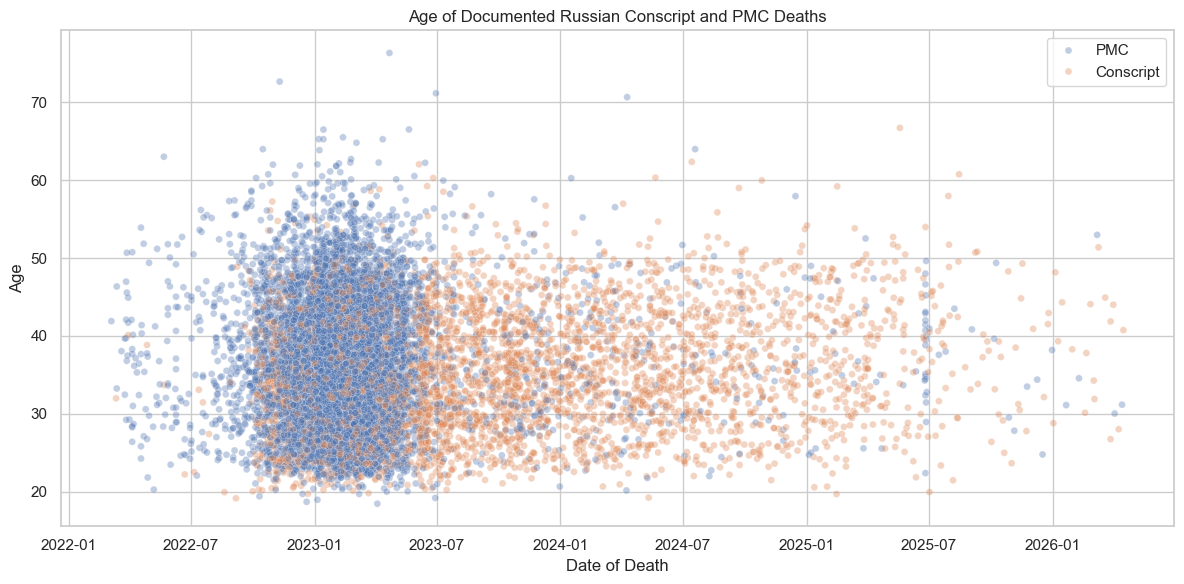

<Figure size 640x480 with 0 Axes>

In [41]:
plot_data = poteru[
    poteru["Age"].notna()
    & (poteru["Age"] > 0)
    & poteru["Date_1"].notna()
    & ((poteru["FlagConscript"] == 1) | (poteru["FlagPMC"] == 1))
].copy()

plot_data["Category"] = "Other"
plot_data.loc[plot_data["FlagConscript"] == 1, "Category"] = "Conscript"
plot_data.loc[plot_data["FlagPMC"] == 1, "Category"] = "PMC"

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=plot_data,
    x="Date_1",
    y="Age",
    hue="Category",
    alpha=0.35,
    s=25
)

plt.title("Age of Documented Russian Conscript and PMC Deaths")
plt.xlabel("Date of Death")
plt.ylabel("Age")
plt.legend(title="")
plt.tight_layout()
plt.show()


plt.savefig(
    "figures/age_pmc_conscripts",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

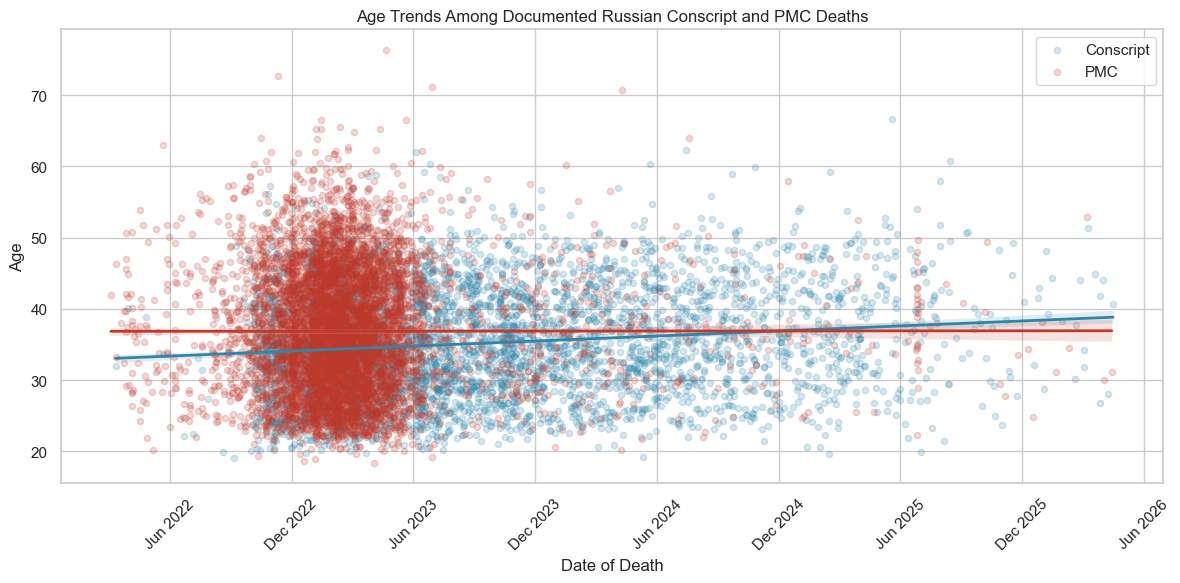

<Figure size 640x480 with 0 Axes>

In [42]:
plot_data = poteru[
    poteru["Age"].notna()
    & (poteru["Age"] > 0)
    & poteru["Date_1"].notna()
    & ((poteru["FlagConscript"] == 1) | (poteru["FlagPMC"] == 1))
].copy()

plot_data["Category"] = "PMC"
plot_data.loc[plot_data["FlagConscript"] == 1, "Category"] = "Conscript"

plot_data["DateNumeric"] = mdates.date2num(plot_data["Date_1"])

colors = {
    "Conscript": "#2E86AB",
    "PMC": "#C0392B"
}

fig, ax = plt.subplots(figsize=(12, 6))

for category, color in colors.items():
    subset = plot_data[plot_data["Category"] == category]

    sns.regplot(
        data=subset,
        x="DateNumeric",
        y="Age",
        scatter_kws={"alpha": 0.2, "s": 20},
        line_kws={"linewidth": 2},
        color=color,
        label=category,
        ci=95,
        ax=ax
    )

ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.set_title("Age Trends Among Documented Russian Conscript and PMC Deaths")
ax.set_xlabel("Date of Death")
ax.set_ylabel("Age")
ax.legend(title="")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.savefig(
    "figures/age_pmc_conscripts_linreg",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

In [43]:

sns.set_theme(style="whitegrid")

poteru["Age"] = pd.to_numeric(poteru["Age"], errors="coerce")
poteru["Date_1"] = pd.to_datetime(poteru["Date_1"], errors="coerce")

poteru["FlagPMC"] = pd.to_numeric(
    poteru["FlagPMC"], errors="coerce"
).fillna(0)

poteru["FlagConscript"] = pd.to_numeric(
    poteru["FlagConscript"], errors="coerce"
).fillna(0)

conscripts = poteru[poteru["FlagConscript"] == 1].copy()
conscripts["Category"] = "Conscript"

pmcs = poteru[poteru["FlagPMC"] == 1].copy()
pmcs["Category"] = "PMC"

plot_data = pd.concat([conscripts, pmcs], ignore_index=True)

plot_data = plot_data[
    plot_data["Age"].notna()
    & plot_data["Age"].between(15, 90)
].copy()

colors = {
    "Conscript": "#2E86AB",
    "PMC": "#C0392B"
}

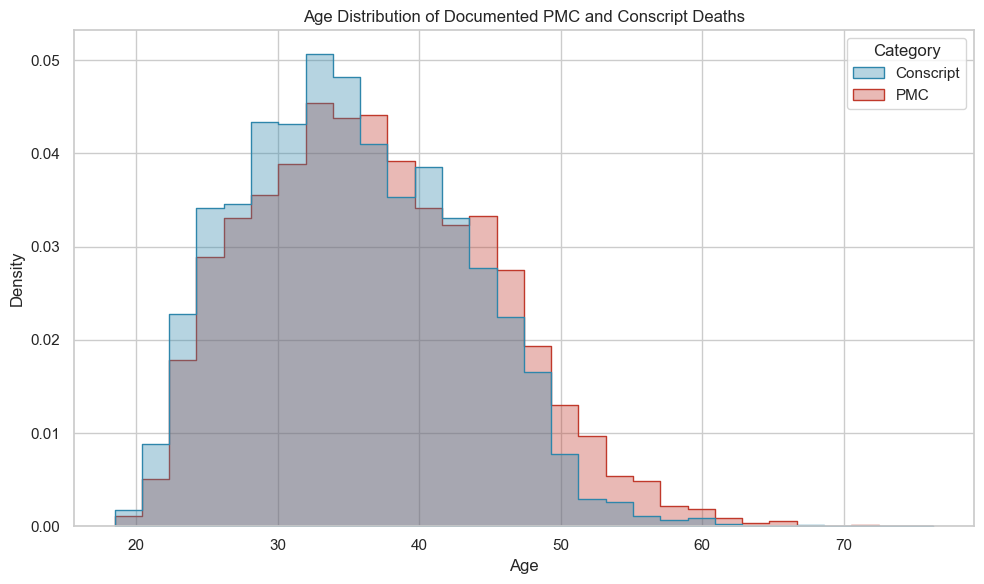

<Figure size 640x480 with 0 Axes>

In [44]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=plot_data,
    x="Age",
    hue="Category",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.35,
    palette=colors
)

plt.title("Age Distribution of Documented PMC and Conscript Deaths")
plt.xlabel("Age")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

plt.savefig(
    "figures/Age_Distribution_PMC_Conscript",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

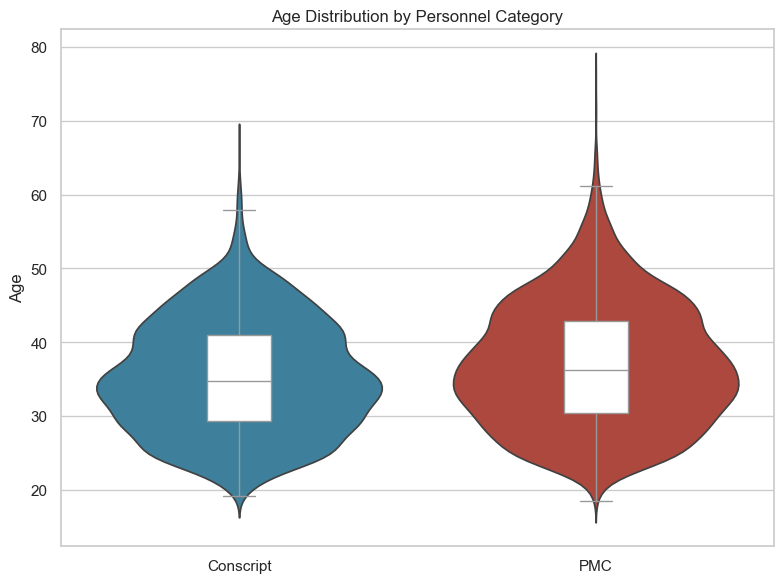

<Figure size 640x480 with 0 Axes>

In [45]:
plt.figure(figsize=(8, 6))

sns.violinplot(
    data=plot_data,
    x="Category",
    y="Age",
    hue="Category",
    palette=colors,
    inner=None,
    legend=False
)

sns.boxplot(
    data=plot_data,
    x="Category",
    y="Age",
    width=0.18,
    showfliers=False,
    color="white"
)

plt.title("Age Distribution by Personnel Category")
plt.xlabel("")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

plt.savefig(
    "figures/Age_Distribution_PMC_Conscript_violin",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

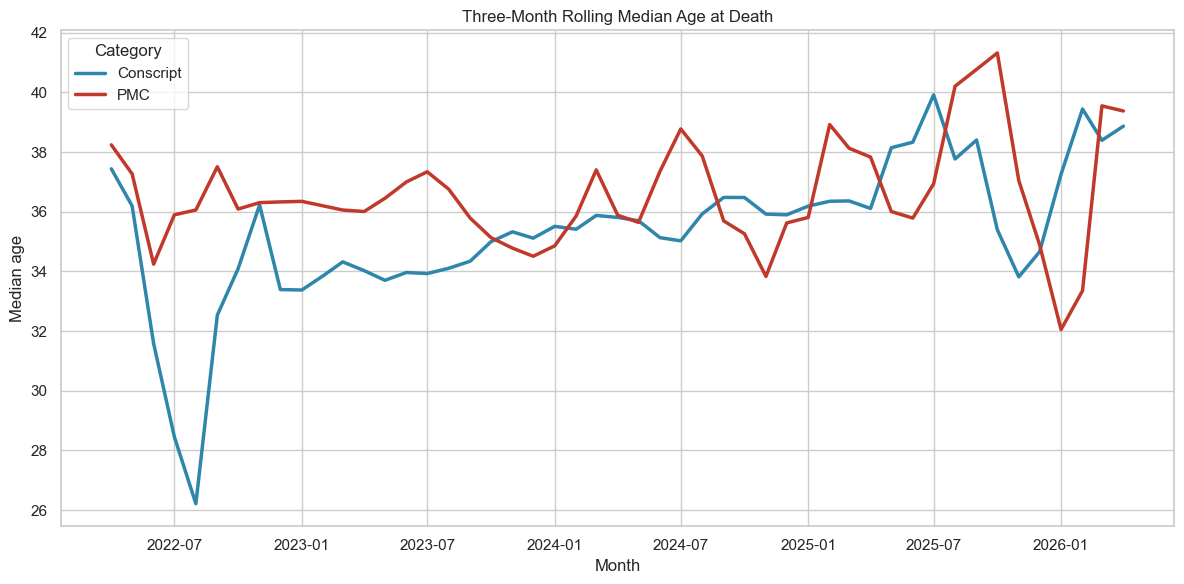

<Figure size 640x480 with 0 Axes>

In [46]:
monthly_age = (
    plot_data.dropna(subset=["Date_1"])
    .groupby([
        pd.Grouper(key="Date_1", freq="MS"),
        "Category"
    ])["Age"]
    .median()
    .reset_index(name="MedianAge")
    .sort_values(["Category", "Date_1"])
)

monthly_age["RollingMedianAge"] = (
    monthly_age.groupby("Category")["MedianAge"]
    .transform(lambda x: x.rolling(3, min_periods=2).mean())
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_age,
    x="Date_1",
    y="RollingMedianAge",
    hue="Category",
    palette=colors,
    linewidth=2.5
)

plt.title("Three-Month Rolling Median Age at Death")
plt.xlabel("Month")
plt.ylabel("Median age")
plt.tight_layout()
plt.show()

plt.savefig(
    "figures/Three_Month_Rolling_Median_Age_PMC_Conscript",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

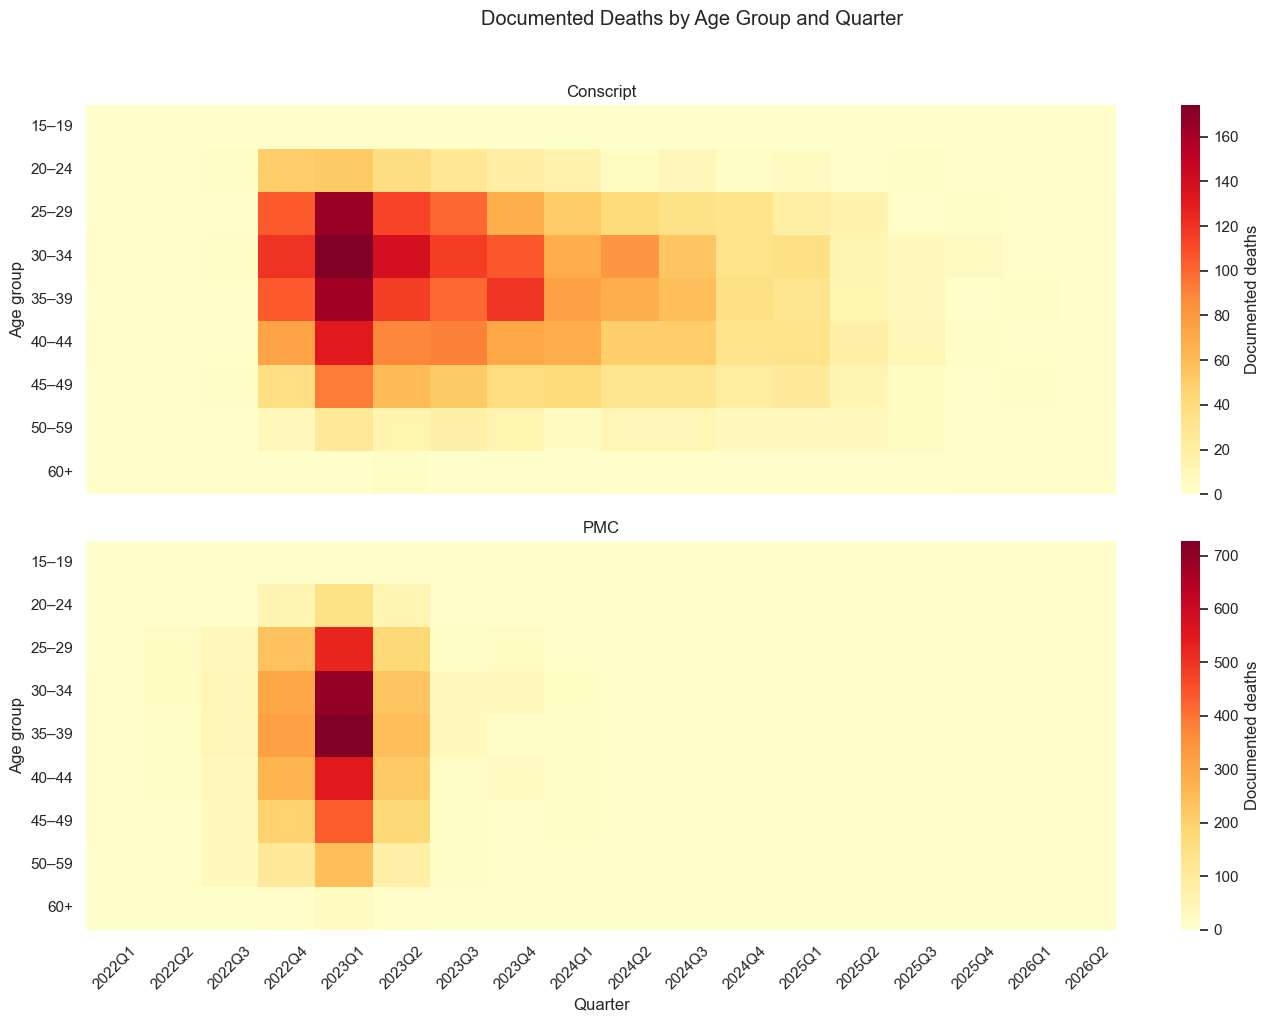

<Figure size 640x480 with 0 Axes>

In [47]:
heatmap_data = plot_data.dropna(subset=["Date_1"]).copy()

heatmap_data["AgeGroup"] = pd.cut(
    heatmap_data["Age"],
    bins=[15, 19, 24, 29, 34, 39, 44, 49, 59, 100],
    labels=[
        "15–19", "20–24", "25–29", "30–34",
        "35–39", "40–44", "45–49", "50–59", "60+"
    ]
)

heatmap_data["Quarter"] = (
    heatmap_data["Date_1"].dt.to_period("Q").astype(str)
)

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

for ax, category in zip(axes, ["Conscript", "PMC"]):
    table = (
        heatmap_data[heatmap_data["Category"] == category]
        .groupby(["AgeGroup", "Quarter"], observed=False)
        .size()
        .unstack(fill_value=0)
    )

    sns.heatmap(
        table,
        cmap="YlOrRd",
        ax=ax,
        cbar_kws={"label": "Documented deaths"}
    )

    ax.set_title(category)
    ax.set_xlabel("")
    ax.set_ylabel("Age group")

axes[-1].set_xlabel("Quarter")
plt.xticks(rotation=45)
plt.suptitle("Documented Deaths by Age Group and Quarter", y=1.02)
plt.tight_layout()
plt.show()

plt.savefig(
    "figures/Heatmap_Documented_Deaths_by_Age_Group_and_Quarter",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

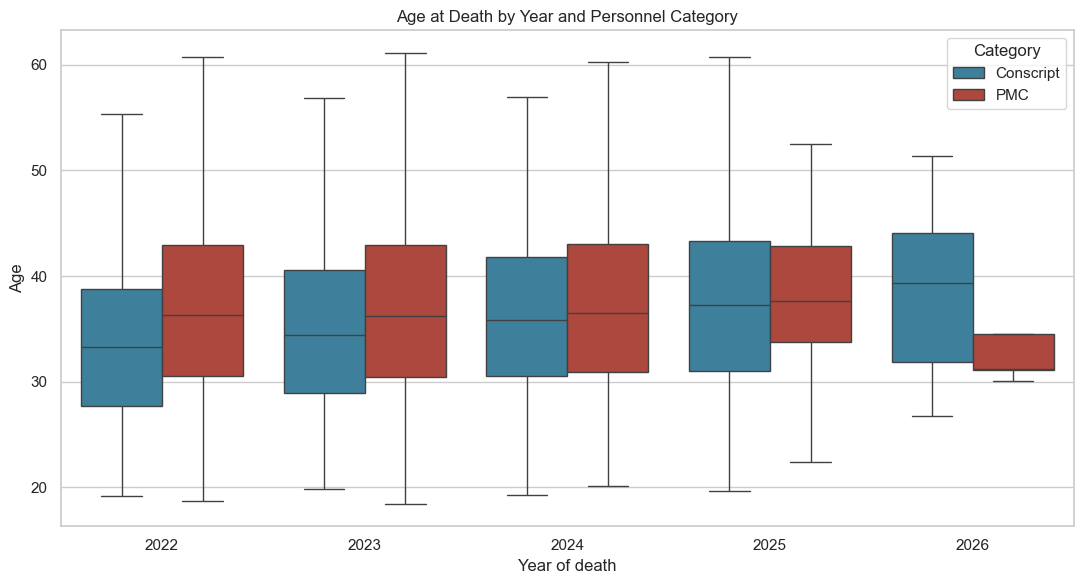

<Figure size 640x480 with 0 Axes>

In [48]:
year_data = plot_data.dropna(subset=["Date_1"]).copy()
year_data["Year"] = year_data["Date_1"].dt.year

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=year_data,
    x="Year",
    y="Age",
    hue="Category",
    palette=colors,
    showfliers=False
)

plt.title("Age at Death by Year and Personnel Category")
plt.xlabel("Year of death")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

plt.savefig(
    "figures/Age_at_Death_by_Year_and_Personnel_Category",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

C:\Users\lucas\AppData\Local\Temp\ipykernel_29840\3061098536.py:67: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


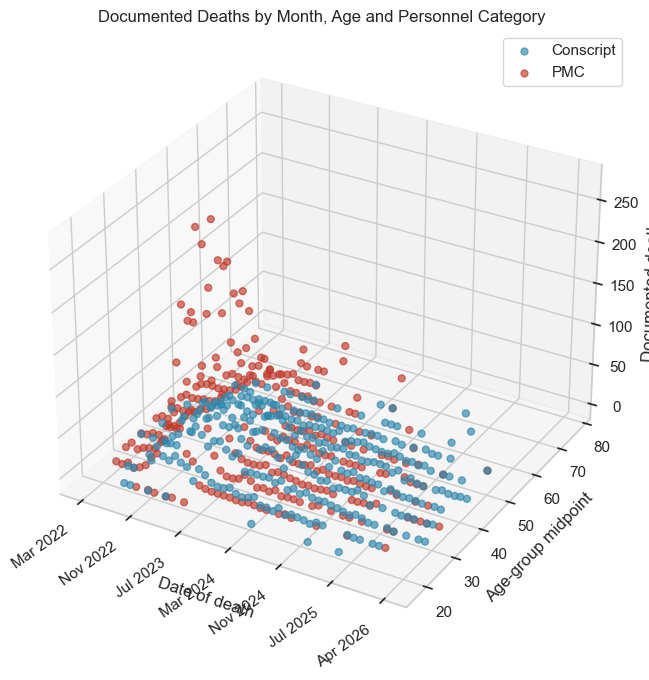

<Figure size 640x480 with 0 Axes>

In [49]:
from mpl_toolkits.mplot3d import Axes3D

three_d = plot_data.dropna(subset=["Date_1", "Age"]).copy()

three_d["Month"] = three_d["Date_1"].dt.to_period("M").dt.to_timestamp()

three_d["AgeGroup"] = pd.cut(
    three_d["Age"],
    bins=np.arange(15, 86, 5),
    right=False
)

three_d["AgeMidpoint"] = three_d["AgeGroup"].apply(
    lambda interval: interval.mid if pd.notna(interval) else np.nan
).astype(float)

three_d = (
    three_d.groupby(
        ["Month", "AgeMidpoint", "Category"],
        observed=True
    )
    .size()
    .reset_index(name="Deaths")
)

three_d["MonthNumeric"] = mdates.date2num(three_d["Month"])

fig = plt.figure(figsize=(13, 8))
ax = fig.add_subplot(111, projection="3d")

for category, color in colors.items():
    subset = three_d[three_d["Category"] == category]

    ax.scatter(
        subset["MonthNumeric"],
        subset["AgeMidpoint"],
        subset["Deaths"],
        color=color,
        alpha=0.65,
        s=25,
        label=category
    )

# Format date ticks
date_ticks = np.linspace(
    three_d["MonthNumeric"].min(),
    three_d["MonthNumeric"].max(),
    7
)

ax.set_xticks(date_ticks)
ax.set_xticklabels(
    [
        mdates.num2date(date).strftime("%b %Y")
        for date in date_ticks
    ],
    rotation=35,
    ha="right"
)

ax.set_title("Documented Deaths by Month, Age and Personnel Category")
ax.set_xlabel("Date of death")
ax.set_ylabel("Age-group midpoint")
ax.set_zlabel("Documented deaths")
ax.legend()

plt.tight_layout()
plt.show()

plt.savefig(
    "figures/3D_Heatmap_Documented_Deaths_by_Month_Age_and_Personnel_Category",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)